# Proyecto final – Modelos y Simulación de Sistemas II (UdeA)
## Notebook 2 · Entrenamiento y evaluación de modelos (Sección 4 de la guía)

**Problema:** predecir, al momento del alta, si un paciente diabético será readmitido en menos de 30 días
(*Diabetes 130-US Hospitals*, 1999–2008).

Este notebook cubre los puntos 5–8 de la guía:

1. **Metodología de validación** (y la justificación experimental de las decisiones de diseño señaladas en la revisión del avance 1).
2. **Malla de hiperparámetros** de cada modelo.
3. **Métricas** de desempeño y su justificación.
4. **Resultados** de entrenamiento, validación y prueba con intervalos de confianza.

Modelos comparados (la guía exige al menos 5):

| Tipo exigido por la guía | Modelo |
|---|---|
| Paramétrico basado en regresión | Regresión logística |
| No paramétrico | k vecinos más cercanos (k-NN) |
| Ensamble de árboles de decisión | Random Forest y Gradient Boosting (HistGradientBoosting) |
| Red neuronal artificial | Perceptrón multicapa (MLP) |
| Máquina de vectores de soporte | SVM con kernel RBF |

> **Tiempo de ejecución aproximado en Colab:** 35–45 minutos (2 núcleos). Los resultados se guardan en
> `Proyecto_final/resultados/` y los usa el notebook 3.

## 1. Configuración del entorno

In [1]:
import os, re, glob, json, time, unicodedata, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, ParameterGrid
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             recall_score, f1_score, balanced_accuracy_score)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
SEMILLA = 0

In [2]:
def buscar_carpeta_proyecto(raiz):
    """Busca la carpeta 'Proyecto_final' que contiene data_set/diabetic_data.csv (tolera tildes)."""
    for ruta in glob.glob(os.path.join(raiz, "**", "diabetic_data.csv"), recursive=True):
        ruta_n = unicodedata.normalize("NFC", ruta)
        if "Proyecto_final" in ruta_n:
            carpeta = os.path.dirname(ruta)
            return os.path.dirname(carpeta) if os.path.basename(carpeta) == "data_set" else carpeta
    return None

try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = None
    raiz = "/content/drive/MyDrive"
    candidatas = [os.path.join(raiz, d) for d in os.listdir(raiz)
                  if unicodedata.normalize("NFC", d).startswith("Modelos y Simulaci")]
    for c in candidatas + [raiz]:
        BASE_DIR = buscar_carpeta_proyecto(c)
        if BASE_DIR:
            break
except ImportError:
    BASE_DIR = os.environ.get("PROYECTO_DIR", ".")

if BASE_DIR is None:
    raise FileNotFoundError("No se encontró Proyecto_final/data_set/diabetic_data.csv en el Drive.")

DATA_DIR = os.path.join(BASE_DIR, "data_set")
RES_DIR = os.path.join(BASE_DIR, "resultados")
FIG_DIR = os.path.join(RES_DIR, "figuras")
os.makedirs(FIG_DIR, exist_ok=True)
print("Carpeta del proyecto:", BASE_DIR)

Carpeta del proyecto: /home/claude/proyecto/run


## 2. Carga y preparación de los datos

La preparación se divide en dos partes para **evitar la fuga de información**:

- `cargar_datos()`: transformaciones fila a fila que no usan estadísticas del conjunto (agrupación de
  códigos ICD-9 y administrativos, edad ordinal, `log(1+x)` de los conteos de historial, variables binarias,
  número de fármacos y de cambios de dosis). Se pueden aplicar antes de partir los datos.
- `Preprocesador`: pasos que **sí** usan estadísticas (medicamentos con uso < 0,1 %, las 10 especialidades más
  frecuentes, one-hot y estandarización). Se ajusta **solo con el fold de entrenamiento** y luego se aplica a
  validación y prueba.

Respecto al avance 1 se hacen dos cambios:

1. **Ya no se descartan las hospitalizaciones repetidas**: se usan todas (excepto fallecidos, hospicio y género
   inválido) y la independencia se garantiza con **validación por grupos de paciente** (sección 3.1).
2. **Se elimina `diabetesMed`**: es redundante con `n_diab_meds` (`diabetesMed = Sí` ⇔ `n_diab_meds > 0`;
   V de Cramér = 1,0).

In [3]:
MEDS = ["metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride", "acetohexamide",
        "glipizide", "glyburide", "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose", "miglitol",
        "troglitazone", "tolazamide", "examide", "citoglipton", "insulin", "glyburide-metformin",
        "glipizide-metformin", "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone"]

def grupo_icd9(codigo):
    """Agrupa un código ICD-9 en 9 familias clínicas (Strack et al., 2014)."""
    if pd.isna(codigo):
        return "Missing"
    codigo = str(codigo)
    if codigo[0] in ("V", "E"):
        return "Other"
    x = float(codigo)
    if int(x) == 250:                              return "Diabetes"
    if 390 <= x <= 459 or int(x) == 785:           return "Circulatory"
    if 460 <= x <= 519 or int(x) == 786:           return "Respiratory"
    if 520 <= x <= 579 or int(x) == 787:           return "Digestive"
    if 800 <= x <= 999:                            return "Injury"
    if 710 <= x <= 739:                            return "Musculoskeletal"
    if 580 <= x <= 629 or int(x) == 788:           return "Genitourinary"
    if 140 <= x <= 239:                            return "Neoplasms"
    return "Other"

ADM_TYPE = {1: "Emergency", 2: "Urgent", 3: "Elective", 7: "Emergency",
            4: "Unknown", 5: "Unknown", 6: "Unknown", 8: "Unknown"}

def grupo_alta(i):
    if i == 1:              return "Home"
    if i in (6, 8):         return "Home health"
    if i == 7:              return "Left AMA"
    if i in (18, 25, 26):   return "Unknown"
    return "Transfer"

def grupo_fuente(i):
    if i in (1, 2, 3):                         return "Referral"
    if i == 7:                                 return "Emergency room"
    if i in (4, 5, 6, 10, 18, 22, 25, 26):     return "Transfer"
    return "Unknown"

def cargar_datos(ruta):
    """Lee el CSV original y aplica solo transformaciones fila a fila (no usan estadísticas
    del conjunto, por lo que no generan fuga de información).
    Retorna X (DataFrame), y (0/1) y grupos (patient_nbr)."""
    df = pd.read_csv(ruta, keep_default_na=False, na_values=["?"], low_memory=False)
    df = df[~df["discharge_disposition_id"].isin([11, 13, 14, 19, 20, 21])]   # fallecidos / hospicio
    df = df[df["gender"] != "Unknown/Invalid"].sort_values("encounter_id").reset_index(drop=True)
    y = (df["readmitted"] == "<30").astype(int).values
    grupos = df["patient_nbr"].values
    X = pd.DataFrame(index=df.index)
    X["race"] = df["race"].fillna("Missing")
    X["gender"] = (df["gender"] == "Male").astype(int)
    X["age"] = df["age"].map(lambda s: int(re.findall(r"\d+", s)[0]) // 10)
    X["admission_type"] = df["admission_type_id"].map(ADM_TYPE)
    X["discharge_disposition"] = df["discharge_disposition_id"].map(grupo_alta)
    X["admission_source"] = df["admission_source_id"].map(grupo_fuente)
    X["medical_specialty"] = df["medical_specialty"].fillna("Missing")
    for c in ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications", "number_diagnoses"]:
        X[c] = df[c]
    for c in ["number_outpatient", "number_emergency", "number_inpatient"]:
        X[c] = np.log1p(df[c])
    for c in ["diag_1", "diag_2", "diag_3"]:
        X[c] = df[c].map(grupo_icd9)
    X["max_glu_serum"] = df["max_glu_serum"]
    X["A1Cresult"] = df["A1Cresult"]
    X["change"] = (df["change"] == "Ch").astype(int)
    X["n_diab_meds"] = (df[MEDS] != "No").sum(axis=1)
    X["n_dose_changes"] = df[MEDS].isin(["Up", "Down"]).sum(axis=1)
    for m in MEDS:
        X[m] = df[m]
    # diabetesMed no se incluye: es redundante con n_diab_meds (diabetesMed = 1 <=> n_diab_meds > 0)
    return X, y, grupos


class Preprocesador(BaseEstimator, TransformerMixin):
    """Pasos que SÍ usan estadísticas de los datos; se ajustan solo con el conjunto de entrenamiento:
    - elimina medicamentos usados por menos del 0,1 % de las hospitalizaciones,
    - conserva las 10 especialidades más frecuentes (resto -> 'Other', faltante -> 'Missing'),
    - codificación one-hot de las variables nominales,
    - estandarización de las variables numéricas."""

    def __init__(self, umbral_med=0.001, top_esp=10, escalar=True):
        self.umbral_med = umbral_med
        self.top_esp = top_esp
        self.escalar = escalar

    def fit(self, X, y=None):
        self.meds_ = [m for m in MEDS if (X[m] != "No").mean() >= self.umbral_med]
        esp = X.loc[X["medical_specialty"] != "Missing", "medical_specialty"].value_counts()
        self.top_ = list(esp.index[: self.top_esp])
        self.cat_ = ["race", "admission_type", "discharge_disposition", "admission_source", "medical_specialty",
                     "diag_1", "diag_2", "diag_3", "max_glu_serum", "A1Cresult"] + self.meds_
        self.num_ = ["gender", "age", "time_in_hospital", "num_lab_procedures", "num_procedures",
                     "num_medications", "number_diagnoses", "number_outpatient", "number_emergency",
                     "number_inpatient", "change", "n_diab_meds", "n_dose_changes"]
        Z = self._especialidad(X)
        self.ohe_ = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(Z[self.cat_])
        self.scaler_ = StandardScaler().fit(Z[self.num_]) if self.escalar else None
        self.nombres_ = self.num_ + list(self.ohe_.get_feature_names_out(self.cat_))
        return self

    def _especialidad(self, X):
        Z = X.copy()
        Z["medical_specialty"] = np.where(Z["medical_specialty"].isin(self.top_ + ["Missing"]),
                                          Z["medical_specialty"], "Other")
        return Z

    def transform(self, X):
        Z = self._especialidad(X)
        num = Z[self.num_].values.astype(float)
        if self.scaler_ is not None:
            num = self.scaler_.transform(Z[self.num_])
        return np.hstack([num, self.ohe_.transform(Z[self.cat_])]).astype(np.float32)

In [4]:
X, y, grupos = cargar_datos(os.path.join(DATA_DIR, "diabetic_data.csv"))
print(f"Hospitalizaciones: {len(X):,} | pacientes: {len(np.unique(grupos)):,} | "
      f"variables: {X.shape[1]} | readmitidos <30 días: {y.mean()*100:.2f} %")

Hospitalizaciones: 99,340 | pacientes: 69,987 | variables: 46 | readmitidos <30 días: 11.39 %


In [5]:
# Comprobación de la redundancia entre diabetesMed y n_diab_meds sobre el archivo original
crudo = pd.read_csv(os.path.join(DATA_DIR, "diabetic_data.csv"), keep_default_na=False, na_values=["?"],
                    low_memory=False, usecols=["diabetesMed"] + MEDS)
print(pd.crosstab(crudo["diabetesMed"], (crudo[MEDS] != "No").sum(axis=1) > 0,
                  rownames=["diabetesMed"], colnames=["n_diab_meds > 0"]))
del crudo

n_diab_meds > 0  False  True 
diabetesMed                  
No               23403      0
Yes                  0  78363


## 3. Configuración experimental

### 3.1 Metodología de validación

- **Unidad de análisis:** hospitalización. Un mismo paciente puede tener varias hospitalizaciones, que **no son
  independientes**; si quedaran repartidas entre entrenamiento y evaluación, el modelo se evaluaría sobre
  pacientes que ya conoce (fuga de información).
- **Solución:** validación estratificada **por grupos** (`StratifiedGroupKFold`, vista en la Clase 06 del curso),
  con el paciente (`patient_nbr`) como grupo: todas las hospitalizaciones de un paciente quedan en el mismo
  fold y cada fold conserva la proporción de clases.
- **Esquema:**
  1. 20 % de los pacientes se reservan como **conjunto de prueba** (no se usa hasta el final).
  2. Con el 80 % restante (**desarrollo**) se hace **validación cruzada de 5 folds por grupos** para elegir
     hiperparámetros. Se reportan media e IC 95 % (t de Student, 4 grados de libertad) de entrenamiento y validación.
  3. La mejor configuración se reentrena con todo el conjunto de desarrollo y se evalúa **una sola vez** en prueba;
     el IC de prueba se obtiene por *bootstrap* remuestreando pacientes (1 000 repeticiones).

Antes de entrenar los modelos se justifican experimentalmente las dos decisiones que la revisión del avance 1
pidió soportar: el manejo de pacientes repetidos y el manejo del desbalance.

In [6]:
# Partición entrenamiento+validación (80 %) / prueba (20 %), estratificada y POR PACIENTE:
# todas las hospitalizaciones de un paciente quedan en el mismo conjunto.
sgkf_test = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
idx_dev, idx_test = next(sgkf_test.split(X, y, grupos))
X_dev, y_dev, g_dev = X.iloc[idx_dev].reset_index(drop=True), y[idx_dev], grupos[idx_dev]
X_test, y_test, g_test = X.iloc[idx_test].reset_index(drop=True), y[idx_test], grupos[idx_test]
assert len(set(g_dev) & set(g_test)) == 0, "Hay pacientes compartidos entre desarrollo y prueba"
print(f"Desarrollo: {len(X_dev):,} hospitalizaciones ({len(np.unique(g_dev)):,} pacientes), "
      f"{y_dev.mean()*100:.2f} % positivos")
print(f"Prueba:     {len(X_test):,} hospitalizaciones ({len(np.unique(g_test)):,} pacientes), "
      f"{y_test.mean()*100:.2f} % positivos")

def crear_particiones(X_dev, y_dev, g_dev, n_splits=5, semilla=1):
    """Validación cruzada estratificada por grupos sobre el conjunto de desarrollo.
    El preprocesador se ajusta SOLO con el fold de entrenamiento."""
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=semilla)
    particiones = []
    for tr, va in sgkf.split(X_dev, y_dev, g_dev):
        prep = Preprocesador().fit(X_dev.iloc[tr])
        particiones.append(dict(Xtr=prep.transform(X_dev.iloc[tr]), ytr=y_dev[tr],
                                Xva=prep.transform(X_dev.iloc[va]), yva=y_dev[va],
                                gva=g_dev[va], nombres=prep.nombres_))
    return particiones

Desarrollo: 79,472 hospitalizaciones (56,006 pacientes), 11.39 % positivos
Prueba:     19,868 hospitalizaciones (13,981 pacientes), 11.39 % positivos


In [7]:
def ic95(valores):
    """Media e intervalo de confianza del 95 % (t de Student) a partir de los folds."""
    v = np.asarray(valores, dtype=float)
    m = v.mean()
    h = stats.t.ppf(0.975, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v)) if len(v) > 1 else 0.0
    return m, h

def puntajes(modelo, X):
    """Puntaje continuo del modelo (probabilidad o distancia al hiperplano en la SVM)."""
    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(X)[:, 1]
    return modelo.decision_function(X)

def submuestra_estratificada(n_total, y, n, semilla):
    """Índices de una submuestra estratificada de tamaño n (para la SVM)."""
    rng = np.random.RandomState(semilla)
    idx = []
    for c in (0, 1):
        pos = np.where(y == c)[0]
        k = int(round(n * len(pos) / n_total))
        idx.append(rng.choice(pos, k, replace=False))
    return np.sort(np.concatenate(idx))

def umbral_youden(y_true, s):
    """Umbral que maximiza el índice de Youden J = sensibilidad + especificidad - 1."""
    fpr, tpr, thr = roc_curve(y_true, s)
    return thr[np.argmax(tpr - fpr)]

def metricas_umbral(y_true, s, umbral):
    yp = (s >= umbral).astype(int)
    return dict(sens=recall_score(y_true, yp), esp=recall_score(y_true, yp, pos_label=0),
                bacc=balanced_accuracy_score(y_true, yp), f1=f1_score(y_true, yp))

def experimentar(crear_modelo, malla, particiones, submuestra=None):
    """Recorre la malla de hiperparámetros con validación cruzada por grupos.
    crear_modelo: función que recibe los hiperparámetros y retorna un modelo sin entrenar.
    malla: dict con la lista de valores de cada hiperparámetro.
    submuestra: si no es None, cada modelo se entrena con esa cantidad de muestras del fold.
    Retorna un DataFrame con AUC de entrenamiento y validación (media e IC 95 %) y AUC-PR de validación."""
    resultados = pd.DataFrame()
    for idx, params in enumerate(ParameterGrid(malla)):
        auc_tr, auc_va, ap_va, tiempos = [], [], [], []
        for k, p in enumerate(particiones):
            Xtr, ytr = p["Xtr"], p["ytr"]
            if submuestra is not None:
                sel = submuestra_estratificada(len(ytr), ytr, min(submuestra, len(ytr)), semilla=k)
                Xtr, ytr = Xtr[sel], ytr[sel]
            modelo = crear_modelo(**params)
            t0 = time.time()
            modelo.fit(Xtr, ytr)
            tiempos.append(time.time() - t0)
            s_va = puntajes(modelo, p["Xva"])
            e = submuestra_estratificada(len(ytr), ytr, min(10000, len(ytr)), semilla=100 + k)
            auc_tr.append(roc_auc_score(ytr[e], puntajes(modelo, Xtr[e])))   # AUC de entrenamiento en 10 000 muestras
            auc_va.append(roc_auc_score(p["yva"], s_va))
            ap_va.append(average_precision_score(p["yva"], s_va))
        fila = dict(params)
        fila["AUC entrenamiento"], fila["IC entrenamiento"] = ic95(auc_tr)
        fila["AUC validación"], fila["IC validación"] = ic95(auc_va)
        fila["AUC-PR validación"], fila["IC AUC-PR"] = ic95(ap_va)
        fila["tiempo (s)"] = np.mean(tiempos)
        resultados = pd.concat([resultados, pd.DataFrame([fila])], ignore_index=True)
    return resultados

def predicciones_validacion(crear_modelo, params, particiones, submuestra=None):
    """Entrena la configuración elegida en cada fold y retorna los puntajes de validación,
    para elegir el umbral y calcular métricas dependientes del umbral con su IC."""
    salida = []
    for k, p in enumerate(particiones):
        Xtr, ytr = p["Xtr"], p["ytr"]
        if submuestra is not None:
            sel = submuestra_estratificada(len(ytr), ytr, min(submuestra, len(ytr)), semilla=k)
            Xtr, ytr = Xtr[sel], ytr[sel]
        modelo = crear_modelo(**params).fit(Xtr, ytr)
        e = submuestra_estratificada(len(ytr), ytr, min(10000, len(ytr)), semilla=100 + k)
        salida.append(dict(s_tr=puntajes(modelo, Xtr[e]), ytr=ytr[e], s_va=puntajes(modelo, p["Xva"]), yva=p["yva"]))
    return salida

def bootstrap_por_paciente(y_true, s, grupos_test, umbral, n_boot=1000, semilla=0):
    """IC 95 % en prueba remuestreando PACIENTES con reemplazo (percentiles 2,5 y 97,5)."""
    rng = np.random.RandomState(semilla)
    pacientes, inv = np.unique(grupos_test, return_inverse=True)
    filas_por_paciente = pd.Series(np.arange(len(inv))).groupby(inv).apply(np.array).values
    reg = {k: [] for k in ["auc", "ap", "sens", "esp", "bacc", "f1"]}
    for _ in range(n_boot):
        elegidos = rng.randint(0, len(pacientes), len(pacientes))
        idx = np.concatenate([filas_por_paciente[i] for i in elegidos])
        yt, st = y_true[idx], s[idx]
        reg["auc"].append(roc_auc_score(yt, st)); reg["ap"].append(average_precision_score(yt, st))
        for k, v in metricas_umbral(yt, st, umbral).items():
            reg[k].append(v)
    return {k: np.percentile(v, [2.5, 97.5]) for k, v in reg.items()}

### 3.2 Experimento A: ¿primera hospitalización o validación por grupos?

Se comparan tres esquemas con el **mismo modelo** (Random Forest, 100 árboles, `min_samples_leaf=5`; un modelo
capaz de memorizar muestras hace más visible la fuga) sobre el conjunto de desarrollo:

| Esquema | Datos | Validación |
|---|---|---|
| (a) | Primera hospitalización de cada paciente | `StratifiedKFold` |
| (b) | Todas las hospitalizaciones | `StratifiedKFold` (ignora el paciente → **fuga**) |
| (c) | Todas las hospitalizaciones | `StratifiedGroupKFold` por paciente (**elegido**) |

In [8]:
def experimento_esquemas(X_dev, y_dev, g_dev):
    primera = ~pd.Series(g_dev).duplicated().values      # X_dev está ordenado por encounter_id
    esquemas = {
        "(a) primera hospitalización + StratifiedKFold": (primera, StratifiedKFold(5, shuffle=True, random_state=1), False),
        "(b) todas + StratifiedKFold (con fuga)": (np.ones(len(y_dev), bool), StratifiedKFold(5, shuffle=True, random_state=1), False),
        "(c) todas + StratifiedGroupKFold (por paciente)": (np.ones(len(y_dev), bool), StratifiedGroupKFold(5, shuffle=True, random_state=1), True),
    }
    resultados = pd.DataFrame()
    for nombre, (mascara, cv, por_grupo) in esquemas.items():
        Xs, ys, gs = X_dev[mascara].reset_index(drop=True), y_dev[mascara], g_dev[mascara]
        aucs, compartidos = [], []
        for tr, va in cv.split(Xs, ys, gs if por_grupo else None):
            prep = Preprocesador().fit(Xs.iloc[tr])
            rf = RandomForestClassifier(n_estimators=100, min_samples_leaf=5, class_weight="balanced_subsample",
                                        n_jobs=-1, random_state=SEMILLA)
            rf.fit(prep.transform(Xs.iloc[tr]), ys[tr])
            aucs.append(roc_auc_score(ys[va], rf.predict_proba(prep.transform(Xs.iloc[va]))[:, 1]))
            compartidos.append(np.isin(gs[va], gs[tr]).mean() * 100)
        m, h = ic95(aucs)
        resultados = pd.concat([resultados, pd.DataFrame([{
            "esquema": nombre, "hospitalizaciones": len(ys), "% positivos": ys.mean() * 100,
            "AUC validación": m, "IC 95 %": h,
            "% hosp. de validación con el paciente en entrenamiento": np.mean(compartidos)}])], ignore_index=True)
    return resultados

res_esquemas = experimento_esquemas(X_dev, y_dev, g_dev)
res_esquemas.round(4)

,esquema,hospitalizaciones,% positivos,AUC validación,IC 95 %,% hosp. de validación con el paciente en entrenamiento
0,(a) primera hospitalización + StratifiedKFold,56006,8.9990,0.6398,0.0067,0.0000
1,(b) todas + StratifiedKFold (con fuga),79472,11.3889,0.6644,0.0074,41.5958
2,(c) todas + StratifiedGroupKFold (por paciente),79472,11.3889,0.6599,0.0052,0.0000


**Lectura:**

- En (b), una parte de las hospitalizaciones de validación pertenece a pacientes que el modelo ya vio al entrenar,
  y el AUC sale **inflado** respecto a (c). Esa diferencia es la fuga de información que hay que evitar.
- (c) evita la fuga **sin descartar datos**: usa todas las hospitalizaciones y evalúa siempre sobre pacientes nuevos.
  Por eso se elige (c), como sugirió la revisión del avance.
- El AUC de (a) no es directamente comparable con (c) porque cambia la población: las primeras hospitalizaciones
  tienen menos historial previo y menor tasa de readmisión.

### 3.3 Experimento B: manejo del desbalance

Con ~11 % de positivos, un clasificador que siempre predice "no readmitido" acierta ~89 %. Se consideraron tres
alternativas:

- **Sobremuestreo (SMOTE):** en la literatura con esta base no mostró beneficio: Shang et al. (2021) obtuvieron
  menor AUC con sobremuestreo que con submuestreo en los tres modelos (p. ej., Random Forest 0,640 frente a 0,661),
  y Liu et al. (2024) no compararon contra no balancear. Además genera muestras sintéticas que mezclan categorías
  one-hot. **Se descarta.**
- **Pesos por clase** (*cost-sensitive learning*): se minimiza la pérdida ponderada
  $\frac{1}{n}\sum_i w_{y_i}\,\ell(y_i, f(\mathbf{x}_i))$ con $w_c = \frac{n}{K\,n_c}$ ($K=2$ clases, $n_c$ muestras
  de la clase $c$), la heurística `class_weight="balanced"` de scikit-learn, basada en King y Zeng (2001).
  Solo aplica a modelos que **minimizan una función de pérdida o una impureza**: regresión logística, SVM,
  Random Forest y Gradient Boosting.
- **Elección del umbral de decisión:** el AUC no depende del umbral; las métricas que sí dependen (sensibilidad,
  especificidad, exactitud balanceada, F1) se calculan con el umbral que maximiza el índice de Youden
  $J = \text{sens} + \text{esp} - 1$, elegido **con los datos de validación**. Esto aplica a **todos** los modelos,
  incluidos k-NN (no tiene función de pérdida) y MLP (`MLPClassifier` no admite pesos por clase).

El experimento compara la regresión logística con y sin pesos.

In [9]:
def experimento_pesos(particiones):
    resultados = pd.DataFrame()
    for pesos in [None, "balanced"]:
        aucs, s05, sJ = [], [], []
        for p in particiones:
            m = LogisticRegression(C=0.1, class_weight=pesos, max_iter=2000).fit(p["Xtr"], p["ytr"])
            s_tr, s_va = m.predict_proba(p["Xtr"])[:, 1], m.predict_proba(p["Xva"])[:, 1]
            aucs.append(roc_auc_score(p["yva"], s_va))
            s05.append(recall_score(p["yva"], (s_va >= 0.5).astype(int)))
            u = umbral_youden(p["ytr"], s_tr)
            sJ.append(recall_score(p["yva"], (s_va >= u).astype(int)))
        fila = {"class_weight": str(pesos)}
        fila["AUC validación"], fila["IC AUC"] = ic95(aucs)
        fila["sensibilidad (umbral 0,5)"], fila["IC sens 0,5"] = ic95(s05)
        fila["sensibilidad (umbral Youden)"], fila["IC sens Youden"] = ic95(sJ)
        resultados = pd.concat([resultados, pd.DataFrame([fila])], ignore_index=True)
    return resultados

### 3.4 Particiones de validación cruzada

Se construyen una sola vez los 5 folds (por paciente) del conjunto de desarrollo; el `Preprocesador` se ajusta
dentro de cada fold.

In [10]:
t0 = time.time()
particiones = crear_particiones(X_dev, y_dev, g_dev, n_splits=5, semilla=1)
print(f"{len(particiones)} folds listos en {time.time()-t0:.1f} s")
for k, p in enumerate(particiones):
    print(f"fold {k}: entrenamiento {p['Xtr'].shape}, validación {p['Xva'].shape}, "
          f"positivos val {p['yva'].mean()*100:.2f} %")

5 folds listos en 8.2 s
fold 0: entrenamiento (63577, 126), validación (15895, 126), positivos val 11.39 %
fold 1: entrenamiento (63577, 126), validación (15895, 126), positivos val 11.39 %
fold 2: entrenamiento (63577, 126), validación (15895, 126), positivos val 11.39 %
fold 3: entrenamiento (63580, 125), validación (15892, 125), positivos val 11.39 %
fold 4: entrenamiento (63577, 126), validación (15895, 126), positivos val 11.39 %


In [11]:
res_pesos = experimento_pesos(particiones)
res_pesos.round(4)

,class_weight,AUC validación,IC AUC,"sensibilidad (umbral 0,5)","IC sens 0,5",sensibilidad (umbral Youden),IC sens Youden
0,None,0.6564,0.0112,0.0030,0.0019,0.6112,0.0309
1,balanced,0.6571,0.0101,0.5697,0.0182,0.6213,0.0236


**Lectura:** los pesos por clase casi no cambian el AUC (el ordenamiento de los pacientes por riesgo), pero con
umbral 0,5 el modelo sin pesos prácticamente no detecta readmitidos. Con el umbral de Youden ambos alcanzan una
sensibilidad similar. Conclusión: se usan pesos por clase en los modelos que los admiten y **umbral de Youden
elegido en validación para todos**; no se usa sobremuestreo.

### 3.5 Métricas de desempeño

| Métrica | Por qué |
|---|---|
| **AUC-ROC** (principal) | Mide la capacidad de ordenar pacientes por riesgo; no depende del umbral ni de la proporción de clases. Es la métrica usada en el estado del arte, lo que permite comparar. |
| **AUC-PR** (precisión promedio) | Más sensible al desempeño en la clase minoritaria; referencia: un clasificador aleatorio obtiene la prevalencia (~0,11). |
| Sensibilidad, especificidad | Errores en cada clase con el umbral de Youden. |
| Exactitud balanceada, F1 | Resumen del desempeño con umbral, sin el sesgo de la clase mayoritaria. |

La exactitud (*accuracy*) no se usa como criterio porque el clasificador trivial ya obtiene ~89 %.

## 4. Entrenamiento de los modelos

Para cada modelo se define una función que crea el estimador y una malla de hiperparámetros, y se llama a
`experimentar()`, que recorre la malla con los 5 folds y retorna un DataFrame con el AUC de entrenamiento y
validación (media ± IC 95 %). El criterio de selección es el **mayor AUC de validación**.

In [12]:
def graficar_malla(res, x, hue=None, logx=False, titulo="", ax=None):
    # Efecto de un hiperparámetro en el AUC de entrenamiento (línea discontinua) y validación (continua, IC 95 %)
    ax = ax or plt.gca()
    grupos_hue = [None] if hue is None else sorted(res[hue].astype(str).unique())
    colores = sns.color_palette("tab10", len(grupos_hue))
    for c, g in zip(colores, grupos_hue):
        d = res if g is None else res[res[hue].astype(str) == g]
        d = d.sort_values(x)
        etiqueta = "" if g is None else f"{hue}={g}"
        ax.errorbar(d[x], d["AUC validación"], yerr=d["IC validación"], marker="o", color=c, capsize=3,
                    label=f"validación {etiqueta}".strip())
        ax.plot(d[x], d["AUC entrenamiento"], ls="--", marker=".", color=c, alpha=0.7,
                label=f"entrenamiento {etiqueta}".strip())
    if logx:
        ax.set_xscale("log")
    ax.set_xlabel(x); ax.set_ylabel("AUC-ROC"); ax.set_title(titulo)
    ax.legend(fontsize=7)
    return ax

RESULTADOS_CV = {}
MODELOS = {}

### 4.1 Regresión logística (modelo paramétrico)

$P(y=1\mid\mathbf{x}) = \sigma(\mathbf{w}^\top\mathbf{x} + b)$ con regularización L2. El hiperparámetro $C$ es el
inverso de la fuerza de regularización (menor $C$ → modelo más simple). Pesos por clase balanceados.

In [13]:
def crear_lr(C):
    return LogisticRegression(C=C, class_weight="balanced", max_iter=2000)

malla_lr = {"C": [0.001, 0.01, 0.1, 1, 10]}
t0 = time.time()
res_lr = experimentar(crear_lr, malla_lr, particiones)
print(f"tiempo total: {time.time()-t0:.0f} s")
RESULTADOS_CV["Regresión logística"] = res_lr
MODELOS["Regresión logística"] = dict(crear=crear_lr, submuestra=None)
res_lr.round(4)

tiempo total: 13 s


,C,AUC entrenamiento,IC entrenamiento,AUC validación,IC validación,AUC-PR validación,IC AUC-PR,tiempo (s)
0,0.001,0.6584,0.0062,0.6578,0.0104,0.2019,0.0142,0.1458
1,0.010,0.6618,0.0064,0.6580,0.0100,0.2013,0.0126,0.3124
2,0.100,0.6623,0.0069,0.6571,0.0101,0.2008,0.0119,0.3788
3,1.000,0.6624,0.0070,0.6570,0.0100,0.2008,0.0118,0.7626
4,10.000,0.6623,0.0071,0.6569,0.0100,0.2008,0.0120,0.8938


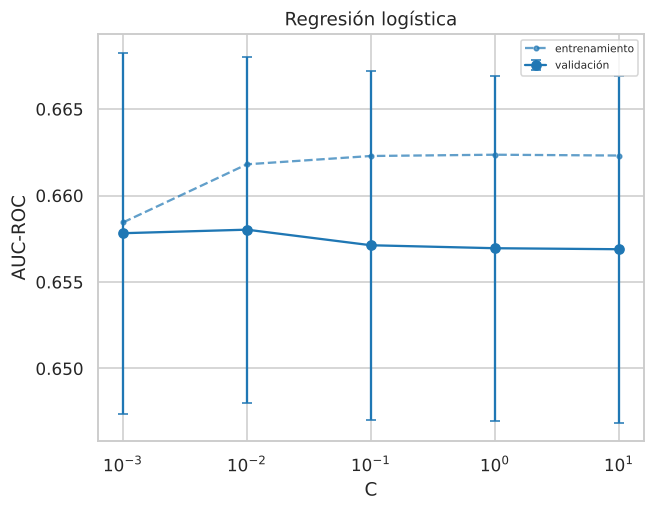

In [14]:
graficar_malla(res_lr, "C", logx=True, titulo="Regresión logística"); plt.show()

### 4.2 k vecinos más cercanos (modelo no paramétrico)

Clasifica según la proporción de readmitidos entre los $k$ vecinos más cercanos (distancia euclidiana sobre las
variables estandarizadas). Hiperparámetros: $k$ y la ponderación de los vecinos (`uniform`: todos pesan igual;
`distance`: pesan según el inverso de la distancia). k-NN no admite pesos por clase; el desbalance se maneja con
el umbral de Youden.

In [15]:
def crear_knn(n_neighbors, weights):
    return KNeighborsClassifier(n_neighbors=n_neighbors, weights=weights, n_jobs=-1)

malla_knn = {"n_neighbors": [5, 25, 75, 150, 300], "weights": ["uniform", "distance"]}
t0 = time.time()
res_knn = experimentar(crear_knn, malla_knn, particiones)
print(f"tiempo total: {time.time()-t0:.0f} s")
RESULTADOS_CV["k-NN"] = res_knn
MODELOS["k-NN"] = dict(crear=crear_knn, submuestra=None)
res_knn.round(4)

tiempo total: 461 s


,n_neighbors,weights,AUC entrenamiento,IC entrenamiento,AUC validación,IC validación,AUC-PR validación,IC AUC-PR,tiempo (s)
0,5,uniform,0.8744,0.0033,0.5613,0.0024,0.1360,0.0020,0.0053
1,5,distance,1.0000,0.0000,0.5619,0.0029,0.1430,0.0036,0.0053
2,25,uniform,0.7367,0.0085,0.6058,0.0088,0.1655,0.0096,0.0057
3,25,distance,1.0000,0.0000,0.6072,0.0078,0.1750,0.0111,0.0054
4,75,uniform,0.6919,0.0065,0.6330,0.0052,0.1868,0.0110,0.0056
5,75,distance,1.0000,0.0000,0.6338,0.0051,0.1926,0.0121,0.0057
6,150,uniform,0.6769,0.0095,0.6438,0.0085,0.1944,0.0099,0.0060
7,150,distance,1.0000,0.0000,0.6443,0.0084,0.1983,0.0108,0.0068
8,300,uniform,0.6640,0.0086,0.6476,0.0088,0.1986,0.0119,0.0057
9,300,distance,1.0000,0.0000,0.6481,0.0087,0.2010,0.0124,0.0050


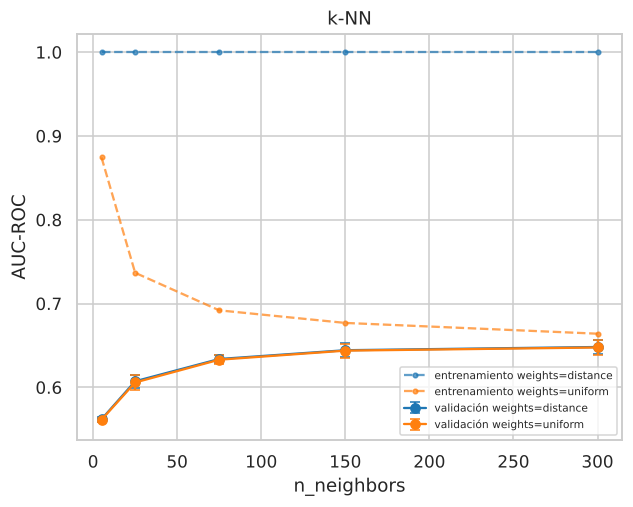

In [16]:
graficar_malla(res_knn, "n_neighbors", hue="weights", titulo="k-NN"); plt.show()

### 4.3 Random Forest (ensamble de árboles por *bagging*)

Promedia árboles entrenados sobre muestras *bootstrap* y subconjuntos aleatorios de variables en cada nodo
(`max_features="sqrt"`). Hiperparámetros: número de árboles y `min_samples_leaf` (tamaño mínimo de las hojas;
valores pequeños → árboles más profundos y mayor riesgo de sobreajuste). Pesos por clase en cada muestra bootstrap.

In [17]:
def crear_rf(n_estimators, min_samples_leaf):
    return RandomForestClassifier(n_estimators=n_estimators, min_samples_leaf=min_samples_leaf,
                                  max_features="sqrt", class_weight="balanced_subsample",
                                  n_jobs=-1, random_state=SEMILLA)

malla_rf = {"n_estimators": [100, 300], "min_samples_leaf": [1, 10, 50]}
t0 = time.time()
res_rf = experimentar(crear_rf, malla_rf, particiones)
print(f"tiempo total: {time.time()-t0:.0f} s")
RESULTADOS_CV["Random Forest"] = res_rf
MODELOS["Random Forest"] = dict(crear=crear_rf, submuestra=None)
res_rf.round(4)

tiempo total: 199 s


,min_samples_leaf,n_estimators,AUC entrenamiento,IC entrenamiento,AUC validación,IC validación,AUC-PR validación,IC AUC-PR,tiempo (s)
0,1,100,1.0000,0.0000,0.6439,0.0055,0.1892,0.0100,3.9012
1,1,300,1.0000,0.0000,0.6532,0.0057,0.1995,0.0101,11.8907
2,10,100,0.9402,0.0018,0.6646,0.0070,0.2083,0.0131,3.0204
3,10,300,0.9438,0.0016,0.6672,0.0070,0.2116,0.0124,8.9872
4,50,100,0.7535,0.0043,0.6655,0.0079,0.2072,0.0139,2.2244
5,50,300,0.7552,0.0037,0.6666,0.0073,0.2075,0.0124,7.1696


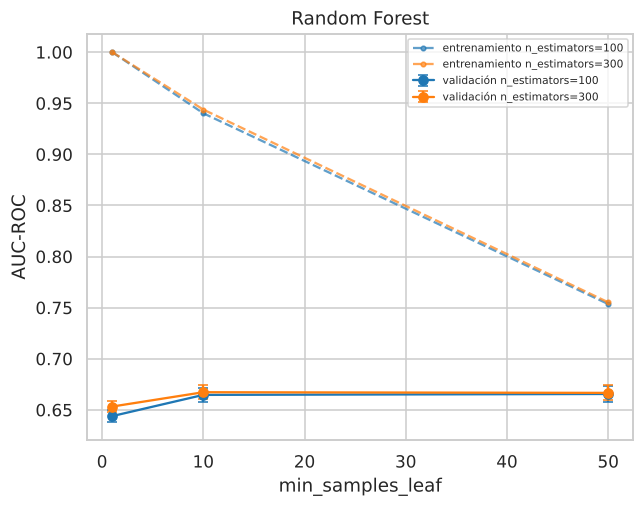

In [18]:
graficar_malla(res_rf, "min_samples_leaf", hue="n_estimators", titulo="Random Forest"); plt.show()

### 4.4 Gradient Boosting (ensamble de árboles por *boosting*)

Árboles agregados secuencialmente; cada uno corrige el error residual (gradiente de la pérdida logística) de los
anteriores. Se usa `HistGradientBoostingClassifier` (equivalente en scikit-learn a XGBoost/LightGBM, los mejores
modelos del estado del arte). Hiperparámetros: tasa de aprendizaje y número máximo de hojas por árbol, con 200
iteraciones. Pesos por clase balanceados.

In [19]:
def crear_gb(learning_rate, max_leaf_nodes):
    return HistGradientBoostingClassifier(learning_rate=learning_rate, max_leaf_nodes=max_leaf_nodes,
                                          max_iter=200, class_weight="balanced", random_state=SEMILLA)

malla_gb = {"learning_rate": [0.03, 0.1], "max_leaf_nodes": [7, 15, 31]}
t0 = time.time()
res_gb = experimentar(crear_gb, malla_gb, particiones)
print(f"tiempo total: {time.time()-t0:.0f} s")
RESULTADOS_CV["Gradient Boosting"] = res_gb
MODELOS["Gradient Boosting"] = dict(crear=crear_gb, submuestra=None)
res_gb.round(4)

tiempo total: 72 s


,learning_rate,max_leaf_nodes,AUC entrenamiento,IC entrenamiento,AUC validación,IC validación,AUC-PR validación,IC AUC-PR,tiempo (s)
0,0.03,7,0.6702,0.0056,0.6627,0.0093,0.2130,0.0160,2.9812
1,0.03,15,0.6903,0.0038,0.6657,0.0096,0.2145,0.0164,3.1217
2,0.03,31,0.7159,0.0110,0.6666,0.0087,0.2144,0.0158,3.4379
3,0.10,7,0.6816,0.0085,0.6636,0.0100,0.2140,0.0150,1.5128
4,0.10,15,0.6960,0.0065,0.6650,0.0094,0.2137,0.0161,1.3258
5,0.10,31,0.7245,0.0154,0.6664,0.0104,0.2143,0.0165,1.3418


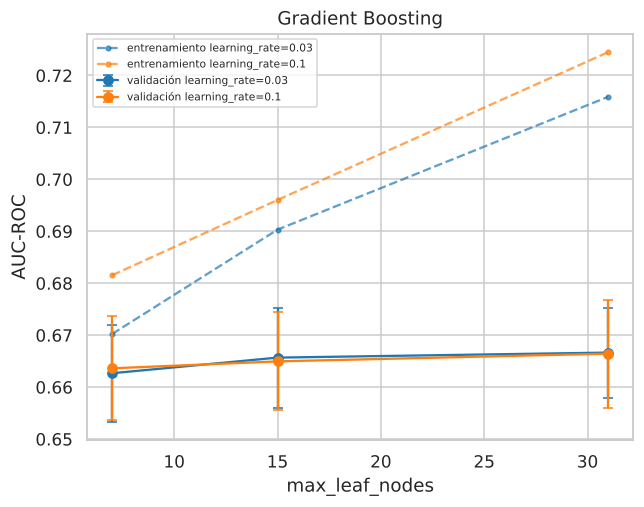

In [20]:
graficar_malla(res_gb, "max_leaf_nodes", hue="learning_rate", titulo="Gradient Boosting"); plt.show()

### 4.5 Perceptrón multicapa (red neuronal artificial)

Red de una o dos capas ocultas con activación ReLU y salida logística, entrenada con Adam y parada temprana
(10 % del entrenamiento como validación interna). Hiperparámetros: arquitectura y regularización L2 (`alpha`).
`MLPClassifier` no admite pesos por clase; el desbalance se maneja con el umbral de Youden.

In [21]:
def crear_mlp(hidden_layer_sizes, alpha):
    return MLPClassifier(hidden_layer_sizes=hidden_layer_sizes, alpha=alpha, early_stopping=True,
                         max_iter=300, random_state=SEMILLA)

malla_mlp = {"hidden_layer_sizes": [(16,), (64,), (64, 32)], "alpha": [1e-4, 1e-2, 1e-1]}
t0 = time.time()
res_mlp = experimentar(crear_mlp, malla_mlp, particiones)
print(f"tiempo total: {time.time()-t0:.0f} s")
res_mlp["hidden_layer_sizes"] = res_mlp["hidden_layer_sizes"].astype(str)
RESULTADOS_CV["MLP"] = res_mlp
MODELOS["MLP"] = dict(crear=crear_mlp, submuestra=None)
res_mlp.round(4)

tiempo total: 91 s


,alpha,hidden_layer_sizes,AUC entrenamiento,IC entrenamiento,AUC validación,IC validación,AUC-PR validación,IC AUC-PR,tiempo (s)
0,0.0001,"(16,)",0.6662,0.0108,0.6554,0.0159,0.2076,0.0160,1.0858
1,0.0001,"(64,)",0.6765,0.0303,0.6564,0.0110,0.2049,0.0142,1.4943
2,0.0001,"(64, 32)",0.6912,0.0169,0.6618,0.0088,0.2100,0.0142,1.8760
3,0.0100,"(16,)",0.6650,0.0106,0.6553,0.0157,0.2078,0.0162,1.0064
4,0.0100,"(64,)",0.6744,0.0193,0.6592,0.0109,0.2092,0.0159,1.6555
5,0.0100,"(64, 32)",0.6845,0.0121,0.6610,0.0082,0.2096,0.0121,1.8344
6,0.1000,"(16,)",0.6619,0.0083,0.6545,0.0156,0.2072,0.0148,1.1150
7,0.1000,"(64,)",0.6727,0.0091,0.6606,0.0113,0.2090,0.0159,3.0968
8,0.1000,"(64, 32)",0.6809,0.0133,0.6622,0.0103,0.2115,0.0163,4.7574


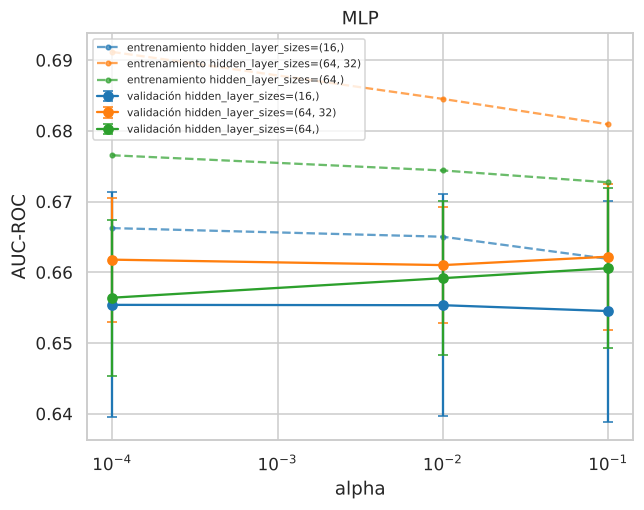

In [22]:
graficar_malla(res_mlp, "alpha", hue="hidden_layer_sizes", logx=True, titulo="MLP"); plt.show()

### 4.6 Máquina de vectores de soporte (kernel RBF)

Busca el hiperplano de máximo margen en el espacio inducido por el kernel
$K(\mathbf{x},\mathbf{x}') = \exp(-\gamma\lVert\mathbf{x}-\mathbf{x}'\rVert^2)$. Hiperparámetros: $C$ (penalización
de errores) y $\gamma$ (ancho del kernel). Pesos por clase balanceados.

**Restricción computacional:** el entrenamiento de una SVM con kernel crece aproximadamente con el cuadrado del
número de muestras; con ~63 000 muestras por fold y una malla de 6 configuraciones no es viable en Colab. Por eso
cada SVM se entrena con una **submuestra estratificada de 8 000 hospitalizaciones** del fold de entrenamiento y se
evalúa sobre el fold de validación completo. El puntaje para el AUC es la distancia al hiperplano
(`decision_function`).

In [23]:
def crear_svm(C, gamma):
    return SVC(C=C, gamma=gamma, kernel="rbf", class_weight="balanced")

N_SVM = 8000
malla_svm = {"C": [0.1, 1, 10], "gamma": [0.003, 0.03]}
t0 = time.time()
res_svm = experimentar(crear_svm, malla_svm, particiones, submuestra=N_SVM)
print(f"tiempo total: {time.time()-t0:.0f} s")
RESULTADOS_CV["SVM (RBF)"] = res_svm
MODELOS["SVM (RBF)"] = dict(crear=crear_svm, submuestra=N_SVM)
res_svm.round(4)

tiempo total: 581 s


,C,gamma,AUC entrenamiento,IC entrenamiento,AUC validación,IC validación,AUC-PR validación,IC AUC-PR,tiempo (s)
0,0.1,0.003,0.6646,0.0095,0.6493,0.0139,0.2008,0.0169,4.9079
1,0.1,0.030,0.7165,0.0074,0.6506,0.0127,0.1920,0.0095,4.0249
2,1.0,0.003,0.6890,0.0092,0.6516,0.0090,0.1957,0.0129,4.2715
3,1.0,0.030,0.8821,0.0029,0.6304,0.0155,0.1762,0.0109,4.1920
4,10.0,0.003,0.7422,0.0074,0.6451,0.0109,0.1892,0.0105,4.4141
5,10.0,0.030,0.9966,0.0006,0.5745,0.0136,0.1465,0.0076,3.5686


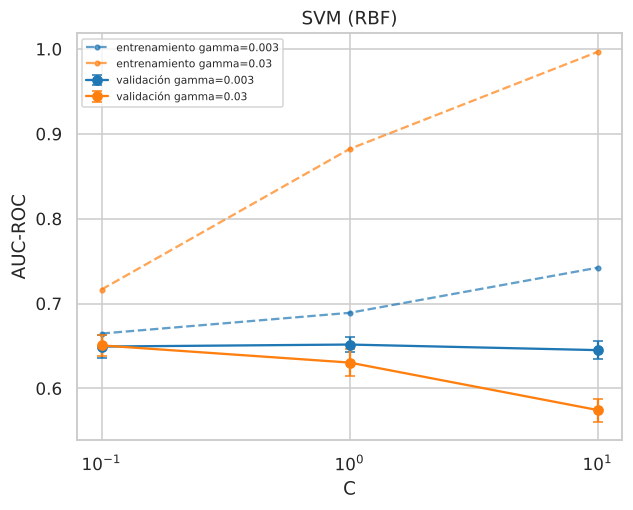

In [24]:
graficar_malla(res_svm, "C", hue="gamma", logx=True, titulo="SVM (RBF)"); plt.show()

### 4.7 Efecto de los hiperparámetros (figura para el informe)

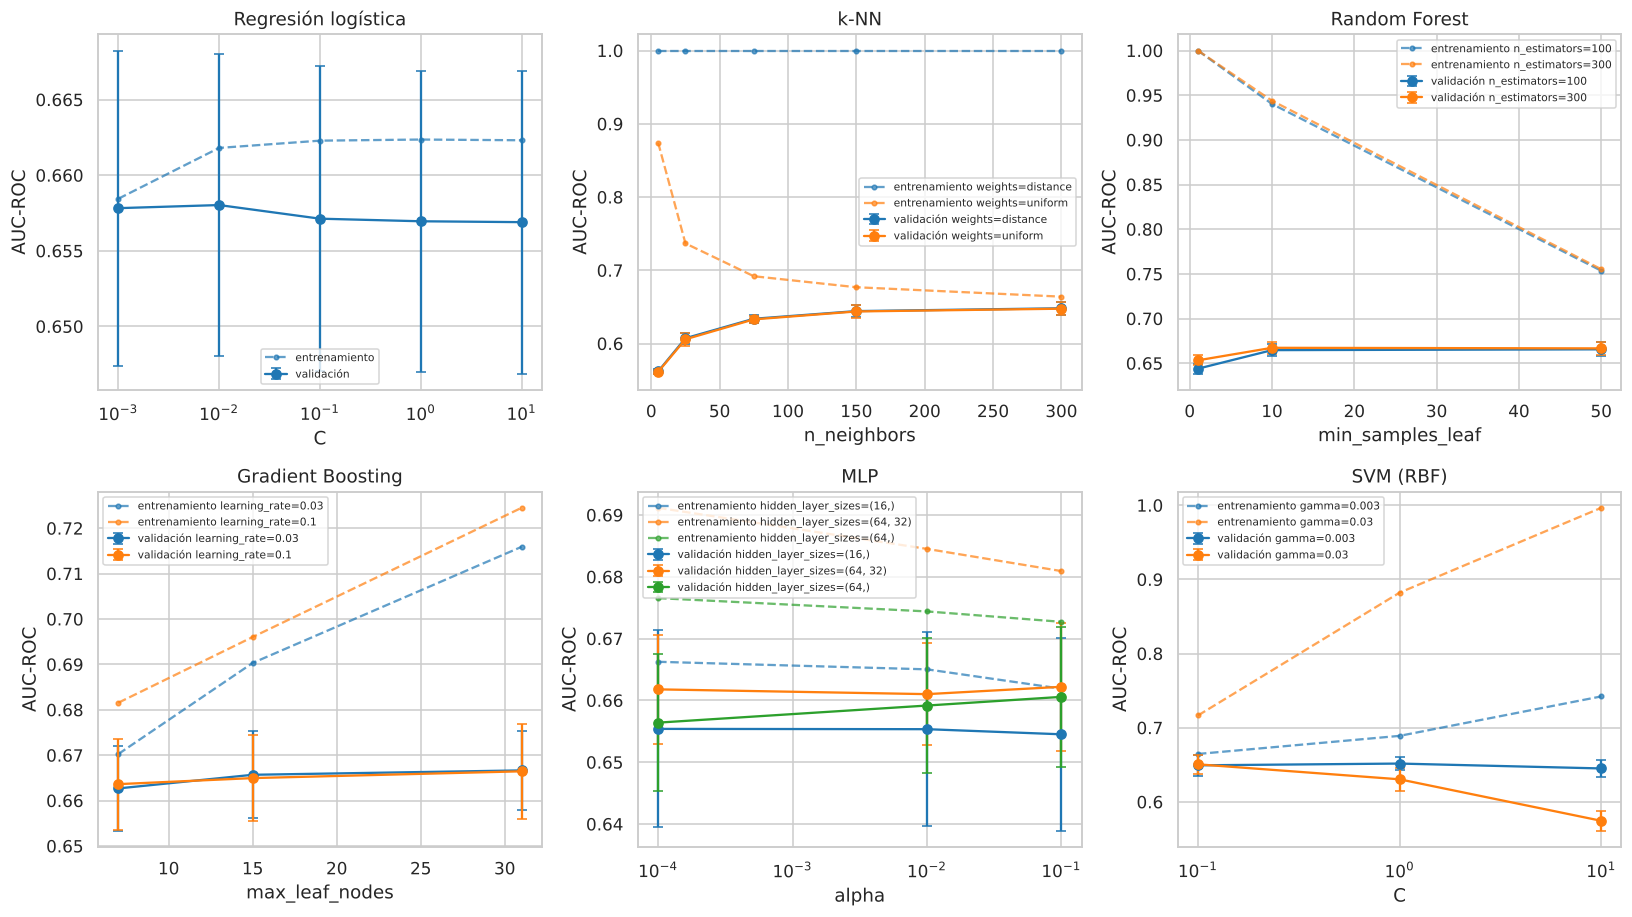

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
graficar_malla(res_lr, "C", logx=True, titulo="Regresión logística", ax=axes[0, 0])
graficar_malla(res_knn, "n_neighbors", hue="weights", titulo="k-NN", ax=axes[0, 1])
graficar_malla(res_rf, "min_samples_leaf", hue="n_estimators", titulo="Random Forest", ax=axes[0, 2])
graficar_malla(res_gb, "max_leaf_nodes", hue="learning_rate", titulo="Gradient Boosting", ax=axes[1, 0])
graficar_malla(res_mlp, "alpha", hue="hidden_layer_sizes", logx=True, titulo="MLP", ax=axes[1, 1])
graficar_malla(res_svm, "C", hue="gamma", logx=True, titulo="SVM (RBF)", ax=axes[1, 2])
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "efecto_hiperparametros.pdf"), bbox_inches="tight")
plt.savefig(os.path.join(FIG_DIR, "efecto_hiperparametros.png"), dpi=150, bbox_inches="tight")
plt.show()

## 5. Selección de la mejor configuración de cada modelo

Para cada modelo se toma la configuración con mayor AUC de validación. Con esa configuración se obtienen las
predicciones de validación de los 5 folds para:

1. Elegir el **umbral de Youden** (con todas las predicciones de validación agrupadas).
2. Calcular sensibilidad, especificidad, exactitud balanceada y F1 de **entrenamiento y validación** con su IC 95 %.

In [26]:
def parametros_de_fila(fila, malla):
    # Recupera los hiperparámetros de una fila de resultados con su tipo original (pandas convierte int -> float)
    params = {}
    for k, valores in malla.items():
        v = fila[k]
        params[k] = next(c for c in valores if str(c) == str(v) or
                         (not isinstance(c, (str, tuple)) and not isinstance(v, str) and np.isclose(c, v)))
    return params

MALLAS = {"Regresión logística": malla_lr, "k-NN": malla_knn, "Random Forest": malla_rf,
          "Gradient Boosting": malla_gb, "MLP": malla_mlp, "SVM (RBF)": malla_svm}
MEJORES = {}
filas = []
for nombre, res in RESULTADOS_CV.items():
    mejor = res.sort_values("AUC validación", ascending=False).iloc[0]
    params = parametros_de_fila(mejor, MALLAS[nombre])
    pv = predicciones_validacion(MODELOS[nombre]["crear"], params, particiones, MODELOS[nombre]["submuestra"])
    umbral = umbral_youden(np.concatenate([d["yva"] for d in pv]), np.concatenate([d["s_va"] for d in pv]))
    met_tr = [metricas_umbral(d["ytr"], d["s_tr"], umbral) for d in pv]
    met_va = [metricas_umbral(d["yva"], d["s_va"], umbral) for d in pv]
    MEJORES[nombre] = dict(params=params, umbral=float(umbral),
                           auc_val=float(mejor["AUC validación"]), ic_val=float(mejor["IC validación"]))
    fila = {"modelo": nombre, "hiperparámetros": str(params),
            "AUC entr.": mejor["AUC entrenamiento"], "IC entr.": mejor["IC entrenamiento"],
            "AUC val.": mejor["AUC validación"], "IC val.": mejor["IC validación"],
            "AUC-PR val.": mejor["AUC-PR validación"], "IC AUC-PR": mejor["IC AUC-PR"]}
    for m in ["sens", "esp", "bacc", "f1"]:
        fila[f"{m} entr."], fila[f"IC {m} entr."] = ic95([d[m] for d in met_tr])
        fila[f"{m} val."], fila[f"IC {m} val."] = ic95([d[m] for d in met_va])
    filas.append(fila)
    print(f"{nombre:20s} {params}  AUC val = {mejor['AUC validación']:.4f} ± {mejor['IC validación']:.4f}")

resumen_cv = pd.DataFrame(filas).sort_values("AUC val.", ascending=False).reset_index(drop=True)
resumen_cv.round(4)

Regresión logística  {'C': 0.01}  AUC val = 0.6580 ± 0.0100


k-NN                 {'n_neighbors': 300, 'weights': 'distance'}  AUC val = 0.6481 ± 0.0087


Random Forest        {'n_estimators': 300, 'min_samples_leaf': 10}  AUC val = 0.6672 ± 0.0070


Gradient Boosting    {'learning_rate': 0.03, 'max_leaf_nodes': 31}  AUC val = 0.6666 ± 0.0087


MLP                  {'hidden_layer_sizes': (64, 32), 'alpha': 0.1}  AUC val = 0.6622 ± 0.0103


SVM (RBF)            {'C': 1, 'gamma': 0.003}  AUC val = 0.6516 ± 0.0090


,modelo,hiperparámetros,AUC entr.,IC entr.,AUC val.,IC val.,AUC-PR val.,IC AUC-PR,sens entr.,IC sens entr.,sens val.,IC sens val.,esp entr.,IC esp entr.,esp val.,IC esp val.,bacc entr.,IC bacc entr.,bacc val.,IC bacc val.,f1 entr.,IC f1 entr.,f1 val.,IC f1 val.
0,Random Forest,"{'n_estimators': 300, 'min_samples_leaf': 10}",0.9438,0.0016,0.6672,0.0070,0.2116,0.0124,0.9874,0.0029,0.6247,0.0108,0.6703,0.0031,0.6171,0.0048,0.8288,0.0015,0.6209,0.0036,0.4338,0.0020,0.2714,0.0026
1,Gradient Boosting,"{'learning_rate': 0.03, 'max_leaf_nodes': 31}",0.7159,0.0110,0.6666,0.0087,0.2144,0.0158,0.6518,0.0151,0.6016,0.0133,0.6476,0.0096,0.6415,0.0073,0.6497,0.0116,0.6215,0.0047,0.2968,0.0101,0.2740,0.0036
2,MLP,"{'hidden_layer_sizes': (64, 32), 'alpha': 0.1}",0.6809,0.0133,0.6622,0.0103,0.2115,0.0163,0.6290,0.0493,0.6102,0.0791,0.6270,0.0722,0.6250,0.0693,0.6280,0.0123,0.6176,0.0098,0.2787,0.0160,0.2697,0.0079
3,Regresión logística,{'C': 0.01},0.6618,0.0064,0.6580,0.0100,0.2013,0.0126,0.6269,0.0080,0.6277,0.0199,0.6021,0.0046,0.6018,0.0017,0.6145,0.0055,0.6147,0.0092,0.2655,0.0043,0.2656,0.0067
4,SVM (RBF),"{'C': 1, 'gamma': 0.003}",0.6890,0.0092,0.6516,0.0090,0.1957,0.0129,0.6586,0.0256,0.6182,0.0329,0.6120,0.0180,0.6077,0.0177,0.6353,0.0083,0.6129,0.0113,0.2816,0.0062,0.2647,0.0082
5,k-NN,"{'n_neighbors': 300, 'weights': 'distance'}",1.0000,0.0000,0.6481,0.0087,0.2010,0.0124,1.0000,0.0000,0.5612,0.0177,1.0000,0.0000,0.6497,0.0078,1.0000,0.0000,0.6054,0.0094,1.0000,0.0000,0.2618,0.0079


## 6. Evaluación final en el conjunto de prueba

Cada modelo se reentrena con **todo el conjunto de desarrollo** (la SVM con una submuestra de 8 000) usando la
configuración y el umbral elegidos en validación, y se evalúa una sola vez en el 20 % de pacientes reservado.

In [27]:
prep_final = Preprocesador().fit(X_dev)
A_dev, A_test = prep_final.transform(X_dev), prep_final.transform(X_test)
print("Dimensión del espacio de características:", A_dev.shape[1])

PUNTAJES_TEST = {}
filas = []
for nombre in resumen_cv["modelo"]:
    info, cfg = MEJORES[nombre], MODELOS[nombre]
    Xa, ya = A_dev, y_dev
    if cfg["submuestra"] is not None:
        sel = submuestra_estratificada(len(ya), ya, cfg["submuestra"], semilla=SEMILLA)
        Xa, ya = Xa[sel], ya[sel]
    t0 = time.time()
    modelo = cfg["crear"](**info["params"]).fit(Xa, ya)
    s = puntajes(modelo, A_test)
    PUNTAJES_TEST[nombre] = s
    met = metricas_umbral(y_test, s, info["umbral"])
    ic = bootstrap_por_paciente(y_test, s, g_test, info["umbral"], n_boot=1000, semilla=SEMILLA)
    fila = {"modelo": nombre, "AUC prueba": roc_auc_score(y_test, s),
            "AUC-PR prueba": average_precision_score(y_test, s)}
    fila.update({f"{k} prueba": v for k, v in met.items()})
    fila.update({f"IC {k}": f"[{v[0]:.3f}, {v[1]:.3f}]" for k, v in ic.items()})
    fila["tiempo (s)"] = time.time() - t0
    filas.append(fila)
    print(f"{nombre:20s} AUC prueba = {fila['AUC prueba']:.4f}  IC {fila['IC auc']}")

resumen_test = pd.DataFrame(filas)
resumen_test.round(4)

Dimensión del espacio de características: 126


Random Forest        AUC prueba = 0.6620  IC [0.650, 0.674]


Gradient Boosting    AUC prueba = 0.6608  IC [0.648, 0.673]


MLP                  AUC prueba = 0.6544  IC [0.642, 0.667]


Regresión logística  AUC prueba = 0.6533  IC [0.641, 0.665]


SVM (RBF)            AUC prueba = 0.6462  IC [0.634, 0.659]


k-NN                 AUC prueba = 0.6408  IC [0.628, 0.654]


,modelo,AUC prueba,AUC-PR prueba,sens prueba,esp prueba,bacc prueba,f1 prueba,IC auc,IC ap,IC sens,IC esp,IC bacc,IC f1,tiempo (s)
0,Random Forest,0.6620,0.1987,0.6284,0.6137,0.6211,0.2712,"[0.650, 0.674]","[0.182, 0.216]","[0.606, 0.649]","[0.605, 0.623]","[0.609, 0.632]","[0.259, 0.283]",27.4258
1,Gradient Boosting,0.6608,0.2015,0.6178,0.6198,0.6188,0.2700,"[0.648, 0.673]","[0.185, 0.219]","[0.596, 0.637]","[0.611, 0.628]","[0.607, 0.629]","[0.257, 0.282]",18.6041
2,MLP,0.6544,0.1967,0.6863,0.5518,0.6190,0.2653,"[0.642, 0.667]","[0.179, 0.215]","[0.667, 0.707]","[0.543, 0.560]","[0.609, 0.629]","[0.254, 0.276]",19.7063
3,Regresión logística,0.6533,0.1921,0.6235,0.5976,0.6105,0.2623,"[0.641, 0.665]","[0.177, 0.209]","[0.603, 0.643]","[0.589, 0.606]","[0.599, 0.621]","[0.250, 0.274]",15.9409
4,SVM (RBF),0.6462,0.1894,0.6103,0.6133,0.6118,0.2643,"[0.634, 0.659]","[0.175, 0.204]","[0.589, 0.631]","[0.604, 0.621]","[0.600, 0.623]","[0.251, 0.276]",30.0494
5,k-NN,0.6408,0.1887,0.5422,0.6443,0.5933,0.2516,"[0.628, 0.654]","[0.173, 0.206]","[0.519, 0.563]","[0.635, 0.653]","[0.582, 0.604]","[0.239, 0.264]",22.3594


### 6.1 Tabla resumen: entrenamiento, validación y prueba

In [28]:
tabla = resumen_cv[["modelo", "AUC entr.", "IC entr.", "AUC val.", "IC val.", "AUC-PR val.", "IC AUC-PR",
                    "bacc val.", "IC bacc val.", "sens val.", "IC sens val."]].merge(
    resumen_test[["modelo", "AUC prueba", "IC auc", "AUC-PR prueba", "bacc prueba", "IC bacc",
                  "sens prueba", "esp prueba", "f1 prueba"]], on="modelo")
tabla.round(4)

,modelo,AUC entr.,IC entr.,AUC val.,IC val.,AUC-PR val.,IC AUC-PR,bacc val.,IC bacc val.,sens val.,IC sens val.,AUC prueba,IC auc,AUC-PR prueba,bacc prueba,IC bacc,sens prueba,esp prueba,f1 prueba
0,Random Forest,0.9438,0.0016,0.6672,0.0070,0.2116,0.0124,0.6209,0.0036,0.6247,0.0108,0.6620,"[0.650, 0.674]",0.1987,0.6211,"[0.609, 0.632]",0.6284,0.6137,0.2712
1,Gradient Boosting,0.7159,0.0110,0.6666,0.0087,0.2144,0.0158,0.6215,0.0047,0.6016,0.0133,0.6608,"[0.648, 0.673]",0.2015,0.6188,"[0.607, 0.629]",0.6178,0.6198,0.2700
2,MLP,0.6809,0.0133,0.6622,0.0103,0.2115,0.0163,0.6176,0.0098,0.6102,0.0791,0.6544,"[0.642, 0.667]",0.1967,0.6190,"[0.609, 0.629]",0.6863,0.5518,0.2653
3,Regresión logística,0.6618,0.0064,0.6580,0.0100,0.2013,0.0126,0.6147,0.0092,0.6277,0.0199,0.6533,"[0.641, 0.665]",0.1921,0.6105,"[0.599, 0.621]",0.6235,0.5976,0.2623
4,SVM (RBF),0.6890,0.0092,0.6516,0.0090,0.1957,0.0129,0.6129,0.0113,0.6182,0.0329,0.6462,"[0.634, 0.659]",0.1894,0.6118,"[0.600, 0.623]",0.6103,0.6133,0.2643
5,k-NN,1.0000,0.0000,0.6481,0.0087,0.2010,0.0124,0.6054,0.0094,0.5612,0.0177,0.6408,"[0.628, 0.654]",0.1887,0.5933,"[0.582, 0.604]",0.5422,0.6443,0.2516


### 6.2 Curvas ROC en prueba

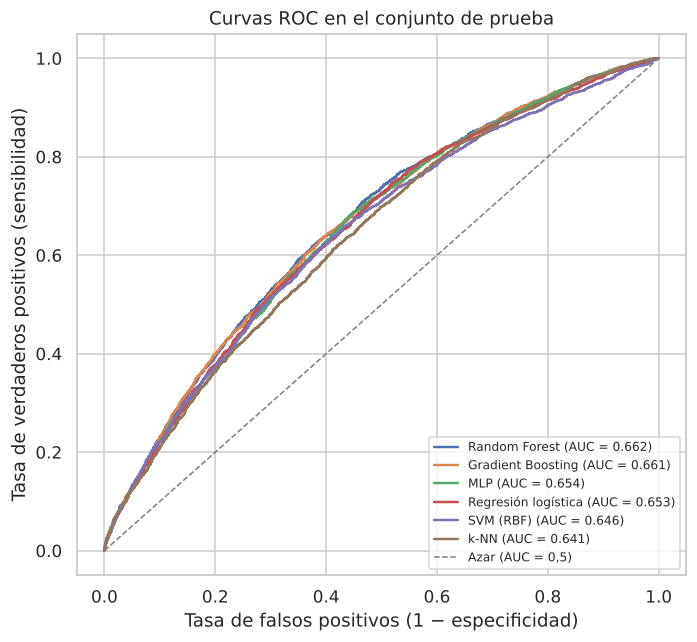

In [29]:
fig, ax = plt.subplots(figsize=(6.5, 6))
for nombre, s in PUNTAJES_TEST.items():
    fpr, tpr, _ = roc_curve(y_test, s)
    ax.plot(fpr, tpr, lw=1.6, label=f"{nombre} (AUC = {roc_auc_score(y_test, s):.3f})")
ax.plot([0, 1], [0, 1], ls="--", color="gray", lw=1, label="Azar (AUC = 0,5)")
ax.set_xlabel("Tasa de falsos positivos (1 − especificidad)")
ax.set_ylabel("Tasa de verdaderos positivos (sensibilidad)")
ax.set_title("Curvas ROC en el conjunto de prueba")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "roc_prueba.pdf"), bbox_inches="tight")
plt.savefig(os.path.join(FIG_DIR, "roc_prueba.png"), dpi=150, bbox_inches="tight")
plt.show()

### 6.3 Comparación de AUC con intervalos de confianza

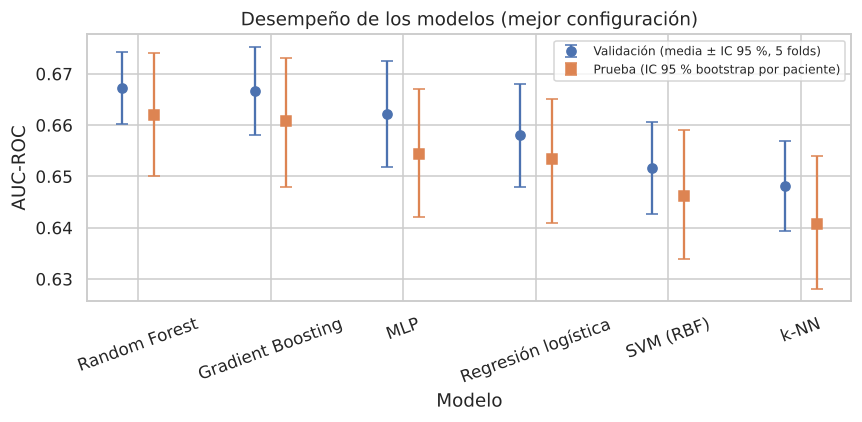

In [30]:
orden = resumen_cv["modelo"].tolist()
fig, ax = plt.subplots(figsize=(8, 4))
pos = np.arange(len(orden))
ax.errorbar(pos - 0.12, resumen_cv["AUC val."], yerr=resumen_cv["IC val."], fmt="o", capsize=4,
            label="Validación (media ± IC 95 %, 5 folds)")
ic_test = np.array([[float(v) for v in re.findall(r"[\d.]+", t)] for t in resumen_test.set_index("modelo").loc[orden, "IC auc"]])
auc_test = resumen_test.set_index("modelo").loc[orden, "AUC prueba"].values
ax.errorbar(pos + 0.12, auc_test, yerr=[auc_test - ic_test[:, 0], ic_test[:, 1] - auc_test], fmt="s", capsize=4,
            label="Prueba (IC 95 % bootstrap por paciente)")
ax.set_xticks(pos); ax.set_xticklabels(orden, rotation=20)
ax.set_xlabel("Modelo"); ax.set_ylabel("AUC-ROC")
ax.set_title("Desempeño de los modelos (mejor configuración)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "auc_modelos.pdf"), bbox_inches="tight")
plt.savefig(os.path.join(FIG_DIR, "auc_modelos.png"), dpi=150, bbox_inches="tight")
plt.show()

## 7. Guardar resultados para el notebook 3 y el informe

In [31]:
for nombre, res in RESULTADOS_CV.items():
    res.to_csv(os.path.join(RES_DIR, f"cv_{re.sub(r'[^a-z]+', '_', unicodedata.normalize('NFKD', nombre.lower()).encode('ascii', 'ignore').decode()).strip('_')}.csv"), index=False)
res_esquemas.to_csv(os.path.join(RES_DIR, "experimento_esquemas.csv"), index=False)
res_pesos.to_csv(os.path.join(RES_DIR, "experimento_pesos.csv"), index=False)
resumen_cv.to_csv(os.path.join(RES_DIR, "resumen_validacion.csv"), index=False)
resumen_test.to_csv(os.path.join(RES_DIR, "resumen_prueba.csv"), index=False)
tabla.to_csv(os.path.join(RES_DIR, "tabla_modelos.csv"), index=False)

def a_json(v):
    return list(v) if isinstance(v, tuple) else v
with open(os.path.join(RES_DIR, "mejores_modelos.json"), "w", encoding="utf-8") as f:
    json.dump({k: dict(v, params={p: a_json(q) for p, q in v["params"].items()}) for k, v in MEJORES.items()},
              f, ensure_ascii=False, indent=2)
print("Archivos guardados en", RES_DIR)
print(sorted(os.listdir(RES_DIR)))

Archivos guardados en /home/claude/proyecto/run/resultados
['cv_gradient_boosting.csv', 'cv_k_nn.csv', 'cv_mlp.csv', 'cv_random_forest.csv', 'cv_regresion_logistica.csv', 'cv_svm_rbf.csv', 'experimento_esquemas.csv', 'experimento_pesos.csv', 'figuras', 'mejores_modelos.json', 'resumen_prueba.csv', 'resumen_validacion.csv', 'tabla_modelos.csv']


## 8. Conclusiones de la Sección 4

Las conclusiones numéricas se leen en las tablas anteriores. En el informe se discuten:

- El ranking de modelos por AUC de validación y su consistencia en prueba.
- La brecha entrenamiento–validación como indicador de sobreajuste (p. ej., Random Forest con hojas de una muestra).
- La comparación con el estado del arte (AUC entre 0,63 y 0,69 con esta misma base).

Los **dos mejores modelos** por AUC de validación se reevalúan en el notebook 3 con selección de variables, PCA y UMAP.